# 07 - PCA curve per algorithm (n_components = 1..50)

For every classifier, sweep the PCA front-end from 1 to 50 components and record 5-fold CV
accuracy (seed 123, PCA fit inside each fold). Answers: how sensitive is each algorithm to the
number of PCs, and where does each peak? Line plot + per-algorithm peak table.

Config: `FEATURE` picks the feature set; `PCA_MAX` the sweep top. Tree/forest estimator counts
are kept modest so the 50-point sweep runs in a few minutes.

In [1]:
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'
import warnings; warnings.filterwarnings('ignore')
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_val_score
DATA='../data'; OUT='../results_withseed'

FEATURE = 'frozen tiny'      # 'frozen tiny' | 'frozen base' | 'handcrafted'
PCA_MAX = 50

paths = {'frozen tiny': f'{OUT}/frozen_tiny.npy',
         'frozen base': f'{OUT}/frozen_base.npy',
         'handcrafted': f'{DATA}/baseline_features.npy'}
X = np.load(paths[FEATURE]); y = np.load(f'{DATA}/preprocessed/labels.npy')
cv = StratifiedKFold(5, shuffle=True, random_state=123); S = 123
n_max = min(PCA_MAX, X.shape[1])           # can't ask for more PCs than features
comps = list(range(1, n_max + 1))
print(f'{FEATURE} {X.shape} | sweeping PCA 1..{n_max}')

frozen tiny (148, 4096) | sweeping PCA 1..50


In [2]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import (LogisticRegression, RidgeClassifier, SGDClassifier,
                                  PassiveAggressiveClassifier)
from sklearn.svm import LinearSVC, SVC
from sklearn.neighbors import KNeighborsClassifier, NearestCentroid
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              HistGradientBoostingClassifier, AdaBoostClassifier,
                              BaggingClassifier, GradientBoostingClassifier)
from sklearn.neural_network import MLPClassifier

# (name, estimator, needs_scale). Modest estimator counts for the 50-point sweep.
SPEC = [
 ('LR L2',           LogisticRegression(max_iter=2000), False),
 ('LR L1',           LogisticRegression(penalty='l1', solver='saga', max_iter=4000), True),
 ('LR ElasticNet',   LogisticRegression(penalty='elasticnet', solver='saga', l1_ratio=0.5, max_iter=4000), True),
 ('Ridge',           RidgeClassifier(), True),
 ('SGD (log)',       SGDClassifier(loss='log_loss', random_state=S), True),
 ('PassiveAggr',     PassiveAggressiveClassifier(random_state=S), True),
 ('Linear SVM',      LinearSVC(max_iter=5000, random_state=S), True),
 ('RBF SVM',         SVC(kernel='rbf', random_state=S), True),
 ('Poly SVM (d3)',   SVC(kernel='poly', degree=3, random_state=S), True),
 ('Sigmoid SVM',     SVC(kernel='sigmoid', random_state=S), True),
 ('kNN k=5',         KNeighborsClassifier(n_neighbors=5), True),
 ('kNN k=15',        KNeighborsClassifier(n_neighbors=15), True),
 ('NearestCentroid', NearestCentroid(), True),
 ('GaussianNB',      GaussianNB(), True),
 ('LDA (shrink)',    LinearDiscriminantAnalysis(solver='lsqr', shrinkage='auto'), True),
 ('RandomForest',    RandomForestClassifier(n_estimators=150, random_state=S, n_jobs=-1), False),
 ('ExtraTrees',      ExtraTreesClassifier(n_estimators=150, random_state=S, n_jobs=-1), False),
 ('GradBoost',       GradientBoostingClassifier(random_state=S), False),
 ('HistGradBoost',   HistGradientBoostingClassifier(random_state=S), False),
 ('AdaBoost',        AdaBoostClassifier(random_state=S), False),
 ('Bagging',         BaggingClassifier(n_estimators=30, random_state=S, n_jobs=-1), False),
 ('MLP (64)',        MLPClassifier(hidden_layer_sizes=(64,), max_iter=1000, random_state=S), True),
 ('MLP (128,64)',    MLPClassifier(hidden_layer_sizes=(128,64), max_iter=1000, random_state=S), True),
]
print(f'{len(SPEC)} classifiers x {len(comps)} PCA settings = {len(SPEC)*len(comps)} points')

23 classifiers x 50 PCA settings = 1150 points


In [3]:
# The 2D sweep: accuracy[algo, n_components]. A few minutes.
curves = {}
for name, clf, needs_scale in SPEC:
    accs = []
    for n in comps:
        steps = [PCA(n_components=n, random_state=S)]
        if needs_scale: steps.append(StandardScaler())
        steps.append(clf)
        accs.append(cross_val_score(make_pipeline(*steps), X, y, cv=cv, scoring='accuracy').mean())
    curves[name] = np.array(accs)
    best_i = int(np.argmax(accs))
    print(f'  {name:20s} peak acc {accs[best_i]:.3f} @ PCA-{comps[best_i]}', flush=True)

  LR L2                peak acc 0.831 @ PCA-8
  LR L1                peak acc 0.811 @ PCA-4
  LR ElasticNet        peak acc 0.804 @ PCA-4
  Ridge                peak acc 0.817 @ PCA-4
  SGD (log)            peak acc 0.804 @ PCA-26
  PassiveAggr          peak acc 0.804 @ PCA-6
  Linear SVM           peak acc 0.811 @ PCA-4
  RBF SVM              peak acc 0.830 @ PCA-9
  Poly SVM (d3)        peak acc 0.729 @ PCA-3
  Sigmoid SVM          peak acc 0.817 @ PCA-43
  kNN k=5              peak acc 0.803 @ PCA-14
  kNN k=15             peak acc 0.797 @ PCA-5
  NearestCentroid      peak acc 0.838 @ PCA-4
  GaussianNB           peak acc 0.797 @ PCA-3
  LDA (shrink)         peak acc 0.824 @ PCA-4
  RandomForest         peak acc 0.837 @ PCA-19
  ExtraTrees           peak acc 0.844 @ PCA-43
  GradBoost            peak acc 0.803 @ PCA-20
  HistGradBoost        peak acc 0.824 @ PCA-11
  AdaBoost             peak acc 0.790 @ PCA-15
  Bagging              peak acc 0.831 @ PCA-12
  MLP (64)             pe

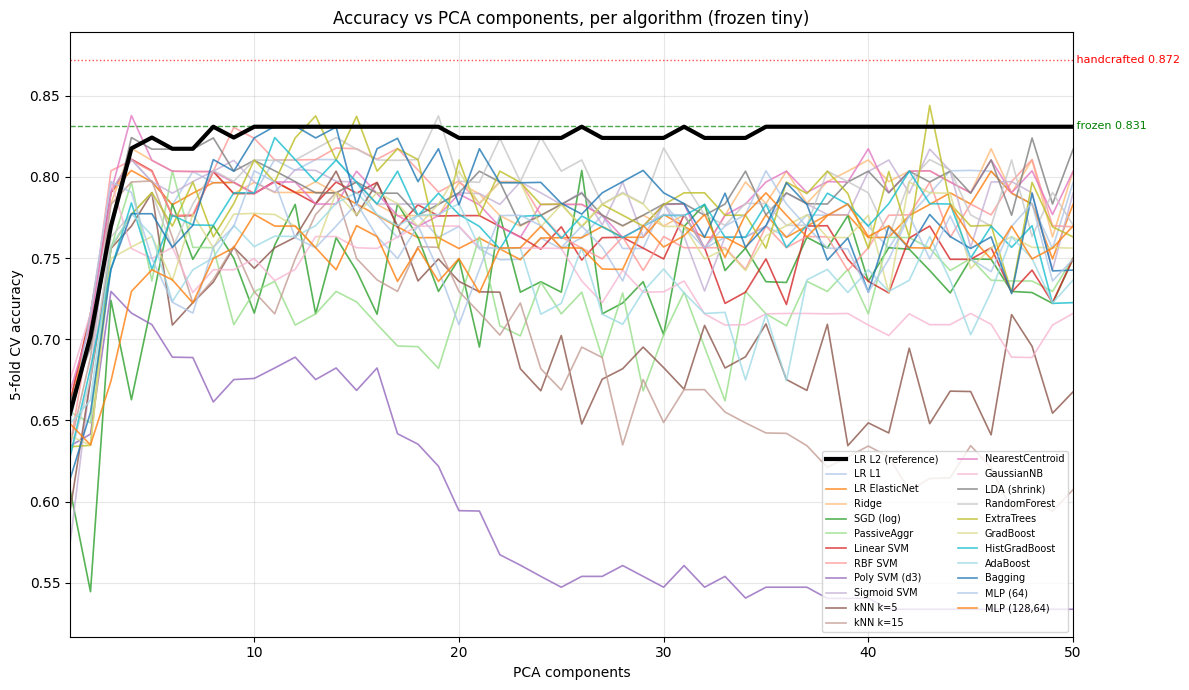

Saved pca_curve_frozen_tiny.png


In [4]:
# Line plot: accuracy vs n_components, one line per algorithm (LR highlighted)
FROZEN_CV, HANDCRAFT_CV = 0.831, 0.872
fig, ax = plt.subplots(figsize=(12, 7))
cmap = plt.get_cmap('tab20')
for i, (name, acc) in enumerate(curves.items()):
    if name == 'LR L2':
        ax.plot(comps, acc, color='black', lw=3, zorder=10, label='LR L2 (reference)')
    else:
        ax.plot(comps, acc, color=cmap(i % 20), lw=1.2, alpha=0.8, label=name)
ax.axhline(FROZEN_CV, color='green', ls='--', lw=1, alpha=0.7)
ax.axhline(HANDCRAFT_CV, color='red', ls=':', lw=1, alpha=0.7)
ax.text(comps[-1], FROZEN_CV, ' frozen 0.831', color='green', va='center', fontsize=8)
ax.text(comps[-1], HANDCRAFT_CV, ' handcrafted 0.872', color='red', va='center', fontsize=8)
ax.set_xlabel('PCA components'); ax.set_ylabel('5-fold CV accuracy')
ax.set_title(f'Accuracy vs PCA components, per algorithm ({FEATURE})')
ax.set_xlim(1, comps[-1]); ax.grid(alpha=0.3); ax.set_axisbelow(True)
ax.legend(fontsize=7, ncol=2, loc='lower right')
plt.tight_layout()
fname = f'pca_curve_{FEATURE.replace(" ","_")}.png'
plt.savefig(os.path.join(OUT, fname), dpi=150); plt.show()
print('Saved', fname)

In [5]:
# Per-algorithm peak, ranked
print(f'{FEATURE} - best PCA setting per algorithm (ranked by peak accuracy):')
peaks = [(name, float(acc.max()), comps[int(np.argmax(acc))]) for name, acc in curves.items()]
peaks.sort(key=lambda r: -r[1])
for name, best, n in peaks:
    print(f'  {name:20s} peak {best:.3f} @ PCA-{n}')

frozen tiny - best PCA setting per algorithm (ranked by peak accuracy):
  ExtraTrees           peak 0.844 @ PCA-43
  NearestCentroid      peak 0.838 @ PCA-4
  RandomForest         peak 0.837 @ PCA-19
  Bagging              peak 0.831 @ PCA-12
  LR L2                peak 0.831 @ PCA-8
  RBF SVM              peak 0.830 @ PCA-9
  LDA (shrink)         peak 0.824 @ PCA-4
  HistGradBoost        peak 0.824 @ PCA-11
  Ridge                peak 0.817 @ PCA-4
  Sigmoid SVM          peak 0.817 @ PCA-43
  Linear SVM           peak 0.811 @ PCA-4
  LR L1                peak 0.811 @ PCA-4
  LR ElasticNet        peak 0.804 @ PCA-4
  SGD (log)            peak 0.804 @ PCA-26
  PassiveAggr          peak 0.804 @ PCA-6
  MLP (64)             peak 0.804 @ PCA-10
  kNN k=5              peak 0.803 @ PCA-14
  GradBoost            peak 0.803 @ PCA-20
  kNN k=15             peak 0.797 @ PCA-5
  GaussianNB           peak 0.797 @ PCA-3
  AdaBoost             peak 0.790 @ PCA-15
  MLP (128,64)         peak 0.790 @ 